# Clustering

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

## Load Data

In [2]:
df = pd.read_csv('AI_Impact_on_Jobs_2030.csv')

## Encode Education

K-Means needs numeric inputs, so education is encoded as an ordinal scale (1–4) that keeps its natural order.

In [3]:
# Encode education as an ordinal scale (1-4) so it can be used in K-Means
education_mapping = {'High School': 1, "Bachelor's": 2, "Master's": 3, 'PhD': 4}
df['Education_Numeric'] = df['Education_Level'].map(education_mapping)

df['Education_Numeric'].value_counts().sort_index()

Education_Numeric
1    784
2    765
3    735
4    716
Name: count, dtype: int64

# K-Means Clustering Analysis

## Business Goal

**Objective:** Discover natural groupings of jobs based on their characteristics (salary, experience, education, skills, AI exposure) to:
- Identify jobs with similar profiles that face comparable AI disruption patterns
- Find which combinations of skills, education, and experience create distinct job archetypes
- Understand if jobs with similar automation probabilities share other characteristics

**Key Questions:**
- Do high-paying jobs cluster together regardless of automation risk?
- Are there skill patterns that define certain job groups?
- Do jobs requiring similar experience/education face similar AI challenges?

**Expected Outcomes:**
- Skill profiles for each cluster
- Insights on which job characteristics correlate with AI vulnerability

## Feature Selecting

In [4]:
features_for_clustering = ['Average_Salary', 'Education_Numeric', 'Automation_Probability_2030']

X = df[features_for_clustering].copy()
X.shape

(3000, 3)

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features_for_clustering)

X_scaled.head()

,Average_Salary,Education_Numeric,Automation_Probability_2030
0,-1.259374,0.482390,1.406136
1,1.271092,1.377362,-1.821754
2,1.642772,-1.307554,1.244741
3,1.362849,1.377362,0.397420
4,-0.548382,-1.307554,0.558815


## Optimal K
Finding the optimal number of clusters (K)

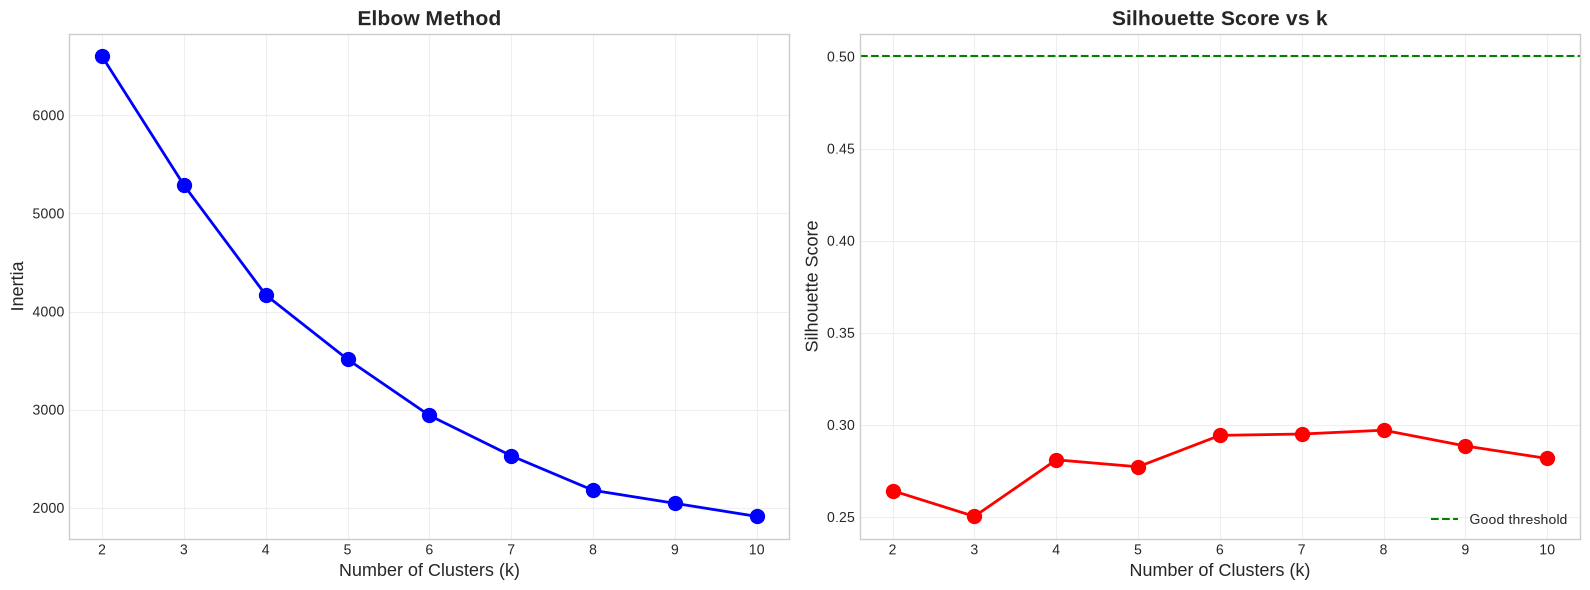

Recommended optimal k: 8 (Silhouette Score: 0.297)


In [6]:
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(K_range, inertias, 'bo-', linewidth=2, markersize=10)
ax1.set_xlabel('Number of Clusters (k)', fontsize=13)
ax1.set_ylabel('Inertia', fontsize=13)
ax1.set_title('Elbow Method', fontsize=15, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(K_range)

ax2.plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=10)
ax2.set_xlabel('Number of Clusters (k)', fontsize=13)
ax2.set_ylabel('Silhouette Score', fontsize=13)
ax2.set_title('Silhouette Score vs k', fontsize=15, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(K_range)
ax2.axhline(y=0.5, color='green', linestyle='--', label='Good threshold')
ax2.legend()

plt.tight_layout()
plt.show()

optimal_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Recommended optimal k: {optimal_k} (Silhouette Score: {max(silhouette_scores):.3f})")

### Choosing k

The metrics barely separate the best candidates: the silhouette score is highest at k = 8 (0.297, against 0.295 at k = 7) and the Davies-Bouldin index is almost the same (0.977 at k = 8, 0.971 at k = 7).

**k = 8** is used because it is also the most interpretable choice. The jobs fall along three axes with two levels each (salary, education and automation risk), so 2 × 2 × 2 = 8 groups. With k = 8 every combination gets its own cluster. With k = 7, two of them would be merged into an artificial "medium risk" cluster that is really a mix of a low-risk and a high-risk group.

## K Means

In [7]:
optimal_k = 8

kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, 
                max_iter=300, random_state=42)

clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters

df['Cluster'].value_counts().sort_index()

Cluster
0    379
1    390
2    402
3    377
4    322
5    402
6    337
7    391
Name: count, dtype: int64

## Cluster Quality

In [8]:
silhouette_avg = silhouette_score(X_scaled, clusters)
davies_bouldin = davies_bouldin_score(X_scaled, clusters)
inertia = kmeans.inertia_

print(f"Silhouette Score: {silhouette_avg:.3f} (> 0.5 is good)")
print(f"Davies-Bouldin Index: {davies_bouldin:.3f} (lower is better)")
print(f"Inertia: {inertia:.2f}")

Silhouette Score: 0.297 (> 0.5 is good)
Davies-Bouldin Index: 0.977 (lower is better)
Inertia: 2178.12


## Visualize Clusters

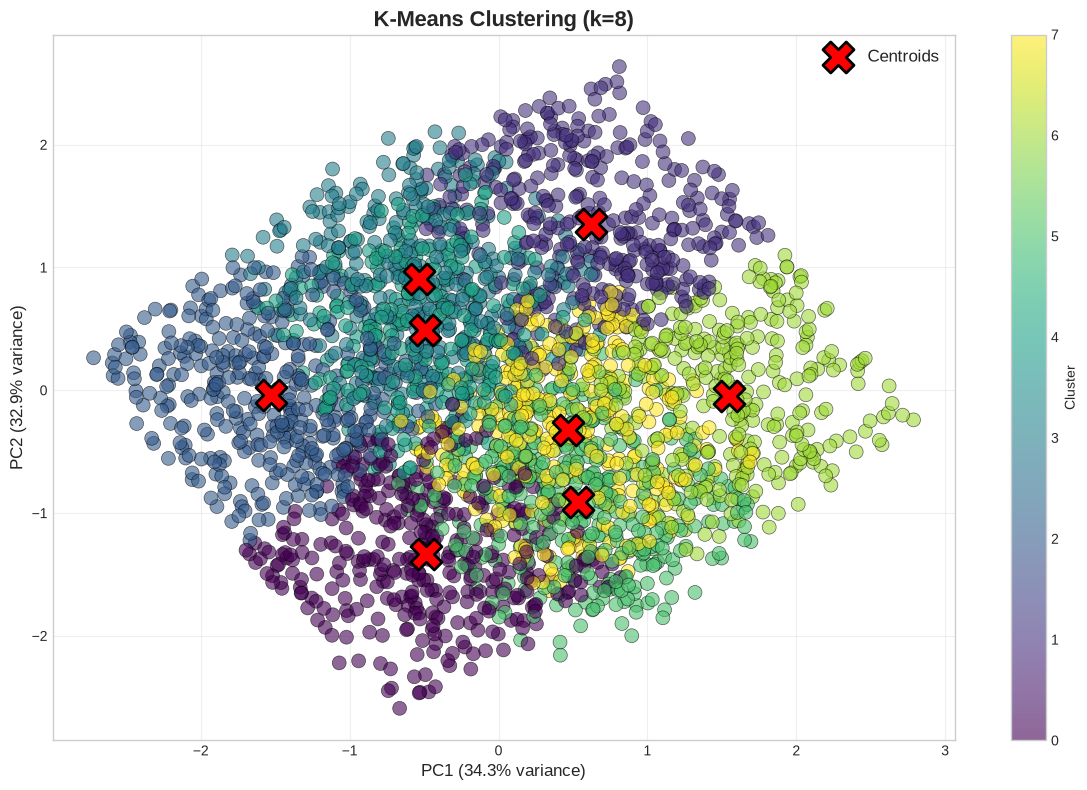

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                     c=clusters, cmap='viridis', 
                     alpha=0.6, edgecolors='black', linewidths=0.5, s=100)

centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1],
           s=500, c='red', marker='X', 
           edgecolors='black', linewidths=2,
           label='Centroids', zorder=5)

plt.title(f'K-Means Clustering (k={optimal_k})', fontsize=16, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
plt.colorbar(scatter, label='Cluster')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cluster Size

         Count  Percentage
Cluster                   
0          379       12.63
1          390       13.00
2          402       13.40
3          377       12.57
4          322       10.73
5          402       13.40
6          337       11.23
7          391       13.03


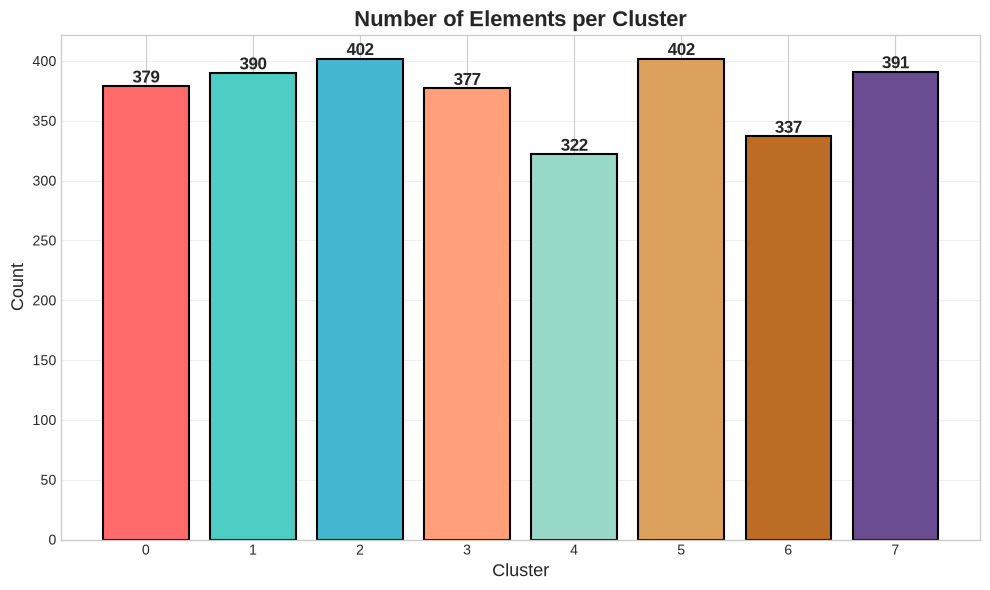

In [10]:
cluster_counts = df['Cluster'].value_counts().sort_index()
cluster_percentages = (cluster_counts / len(df) * 100).round(2)

summary_df = pd.DataFrame({
    'Count': cluster_counts,
    'Percentage': cluster_percentages
})

print(summary_df)

plt.figure(figsize=(10, 6))
bars = plt.bar(cluster_counts.index, cluster_counts.values, 
               color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8', '#DDA15E', '#BC6C25', '#6A4C93'][:optimal_k],
               edgecolor='black', linewidth=1.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title('Number of Elements per Cluster', fontsize=16, fontweight='bold')
plt.xlabel('Cluster', fontsize=13)
plt.ylabel('Count', fontsize=13)
plt.xticks(cluster_counts.index)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Statistical Analysis

In [11]:
for feature in features_for_clustering:
    print(f"\n{'='*60}")
    print(f"FEATURE: {feature}")
    print(f"{'='*60}")
    
    stats = df.groupby('Cluster')[feature].agg([
        ('Count', 'count'),
        ('Mean', 'mean'),
        ('Std Dev', 'std'),
        ('Min', 'min'),
        ('Max', 'max')
    ])
    
    print(stats.round(2))


FEATURE: Average_Salary
         Count       Mean   Std Dev    Min     Max
Cluster                                           
0          379   60991.07  18161.40  30030   91944
1          390  121350.15  16785.89  89816  149798
2          402   57460.97  16392.52  30318   86987
3          377  116100.31  17431.56  86862  149554
4          322   59380.24  17252.49  30234   90628
5          402   60079.96  16795.47  30030   90302
6          337  119515.24  16903.46  88717  149511
7          391  120860.15  17524.67  90587  149756

FEATURE: Education_Numeric
         Count  Mean  Std Dev  Min  Max
Cluster                                
0          379  1.52      0.5    1    2
1          390  3.48      0.5    3    4
2          402  1.47      0.5    1    2
3          377  1.50      0.5    1    2
4          322  3.50      0.5    3    4
5          402  3.53      0.5    3    4
6          337  3.46      0.5    3    4
7          391  1.49      0.5    1    2

FEATURE: Automation_Probability_2030

# K-Means Clustering Analysis - Conclusions

## Cluster Interpretations

Based on the analysis of all 3,000 jobs using Salary, Education and Automation Probability, with k = 8
(education: ~1.5 = High School/Bachelor's, ~3.5 = Master's/PhD):

| Cluster | Share | Salary | Education | Automation Risk | Profile |
|---|---|---|---|---|---|
| 0 | 13% | ~$61k | High School/Bachelor's (1.52) | 29% (LOW) | Lower-paid, lower education, low risk |
| 1 | 13% | ~$121k | Master's/PhD (3.48) | 70% (HIGH) | Well-paid, highly educated, high risk |
| 2 | 13% | ~$57k | High School/Bachelor's (1.47) | 71% (HIGH) | Lower-paid, lower education, high risk |
| 3 | 13% | ~$116k | High School/Bachelor's (1.50) | 71% (HIGH) | Well-paid, lower education, high risk |
| 4 | 11% | ~$59k | Master's/PhD (3.50) | 74% (HIGHEST) | Lower-paid, highly educated, high risk |
| 5 | 13% | ~$60k | Master's/PhD (3.53) | 30% (LOW) | Lower-paid, highly educated, low risk |
| 6 | 11% | ~$120k | Master's/PhD (3.46) | 28% (LOWEST) | Well-paid, highly educated, low risk |
| 7 | 13% | ~$121k | High School/Bachelor's (1.49) | 31% (LOW) | Well-paid, lower education, low risk |

**Cluster 0 - Lower-Paid, Lower-Education, Low-Risk Jobs**: entry-level or hands-on roles with lower pay but relatively safe from automation.

**Cluster 1 - Well-Paid, Highly Educated, High-Risk Jobs**: specialised, well-paid roles that are still highly exposed - likely analytical work that AI can perform.

**Cluster 2 - Lower-Paid, Lower-Education, High-Risk Jobs**: routine, repetitive work - the classic profile of jobs exposed to automation.

**Cluster 3 - Well-Paid, Lower-Education, High-Risk Jobs**: well-paid roles with lower education requirements that are highly vulnerable to automation.

**Cluster 4 - Lower-Paid, Highly Educated, High-Risk Jobs**: highly educated but lower-paid roles, the most exposed group (74%).

**Cluster 5 - Lower-Paid, Highly Educated, Low-Risk Jobs**: highly educated but modestly paid roles (e.g. academia, research, care) that are hard to automate.

**Cluster 6 - Well-Paid, Highly Educated, Low-Risk Jobs**: the safest profile (28%) - highly educated, well-paid and least exposed.

**Cluster 7 - Well-Paid, Lower-Education, Low-Risk Jobs**: well-compensated jobs with lower education requirements and a low automation threat.

## Key Findings

1. **Education ≠ Safety**: Clusters 1 and 4 are mostly Master's/PhD holders, yet face 70-74% automation probability (~24% of all jobs).

2. **Salary ≠ Safety**: Clusters 1 and 3 earn ~$116-121k on average and still face 70-71% automation probability.

3. **Salary and education do not decide the risk**: every combination of salary level and education level appears twice - once with low risk (28-31%) and once with high risk (70-74%), in clusters of similar size. In this dataset, salary and education alone say little about automation risk.

4. **Even split**: the high-risk clusters (1, 2, 3, 4) cover ~50% of jobs and the low-risk clusters (0, 5, 6, 7) the other ~50%.

5. **Sweet Spot**: Cluster 7 combines high salary (~$121k), lower education requirements and low automation risk (31%).

6. **Most Vulnerable**: Cluster 4 - highly educated but lower-paid roles - has the highest automation risk (74%).

## Model Limitations

- Silhouette Score: 0.297 (moderate quality) - clusters overlap significantly
- Automation risk is split around 0.5, so the clusters separate "below/above 50%" rather than the dataset's Low / Medium / High categories
- Only 3 features used; including skills data might reveal different patterns
